# 1. The data

Jordan's results improved sharply from around mid-2022: a 2023 Asian Cup final,
a first World Cup qualification. **Is that shift real once opponent quality is
controlled for, and if so, where did it come from?**

Five notebooks answer that in order. This one answers nothing — it establishes
what there is to answer *with*, so every later claim traces back to a row
somebody can check.

| | |
|---|---|
| **01 — the data** | what exists, how complete, and what it forbids |
| 02 — the strength model | did the results actually shift, and when |
| 03 — the squad and the opposition | who was picked, and who they played |
| 04 — the goals | who scored, when, and in what state |
| 05 — how Jordan can improve | what did not change, and what is still untested |

Three kinds of thing are on disk. A **spine** of 49,547 international matches
from 1872, which decides *which matches exist*. A **squad layer** of lineups,
minutes, goals and events for Jordan. And a set of **model outputs** — the
strength trace and its bootstrap draws — built in notebook 02.

```
cd JordanData
python fbref_fetch.py      # scrape (slow, resumable, cached)
python fbref_parse.py      # HTML -> tidy tables
python wiki_arabcup.py     # the 10 matches FBref does not carry
python wiki_squads.py      # tournament squad lists: clubs and club countries
python merge_sources.py    # combine, with provenance
python match_table.py      # flatten to match and goal grain
python match_state.py      # reconstruct the scoreboard through each match
```

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"])
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
apps = pd.read_csv(SQUAD / "appearances_combined.csv")

## 1. Where every row came from

Two sources, and every row records which. FBref supplies the bulk. Wikipedia
supplies the **ten Arab Cup matches FBref does not carry at all** — including
the entire December 2025 tournament, where Jordan won five of six and reached
the final.

That gap was not random, and section 8 shows what it cost before it was closed.

**Plotted:** the row counts of the three squad tables — matches, Jordan goals
and player-matches — split by the source each row was parsed from. Bars are
shares; the number inside each segment is that segment's row count.

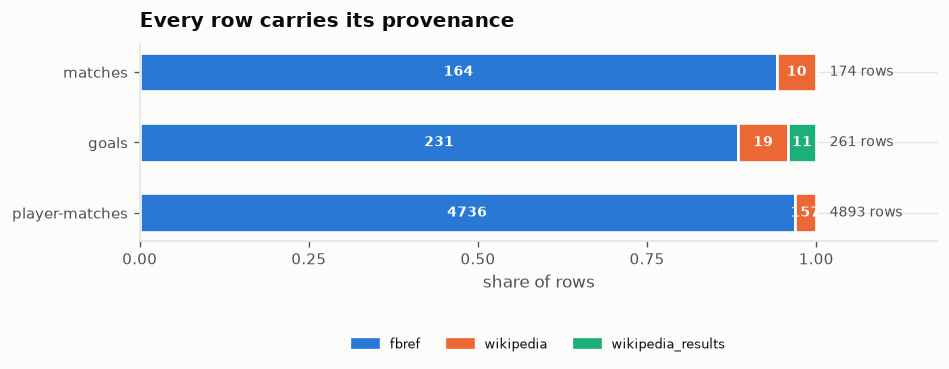

In [2]:
fig, ax = plt.subplots(figsize=(7.8, 2.6))
TAB = [("matches", mt.source), ("goals", goals.source),
       ("player-matches", apps.source)]
SRC = ["fbref", "wikipedia", "wikipedia_results"]
COL = {"fbref": viz.BLUE, "wikipedia": viz.ORANGE, "wikipedia_results": viz.AQUA}
y = np.arange(len(TAB))[::-1]
for i, (lab, s) in enumerate(TAB):
    vc = s.value_counts()
    left = 0
    for k in SRC:
        n = int(vc.get(k, 0))
        if not n:
            continue
        frac = n / vc.sum()
        ax.barh(y[i], frac, left=left, height=0.55, color=COL[k],
                edgecolor=viz.SURFACE, linewidth=1.6)
        ax.annotate(str(n), (left + frac / 2, y[i]), ha="center", va="center",
                    fontsize=8.5, color=viz.SURFACE, fontweight="bold")
        left += frac
    ax.annotate(f"{int(vc.sum())} rows", (1.0, y[i]), xytext=(8, 0), va="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_yticks(y)
ax.set_yticklabels([lab for lab, _ in TAB])
ax.set_xlim(0, 1.18)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel("share of rows")
ax.set_title("Every row carries its provenance")
# handles built by hand: no single bar carries all three sources, so labelling
# one row's segments would silently drop whichever source that row lacks
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[k], label=k)
                   for k in SRC],
          fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.62))
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

## 2. Coverage

The authority for *which matches exist* is `data/results.csv`, not FBref — so a
match FBref lacks appears as a gap rather than vanishing. That distinction is
the whole reason the spine is kept separate.

**Plotted:** every Jordan match since 2015, one bar per year, stacked by whether
a full starting XI was recovered and from where. The grey cap is matches with no
lineup from any source; the note under the axis gives the window total.

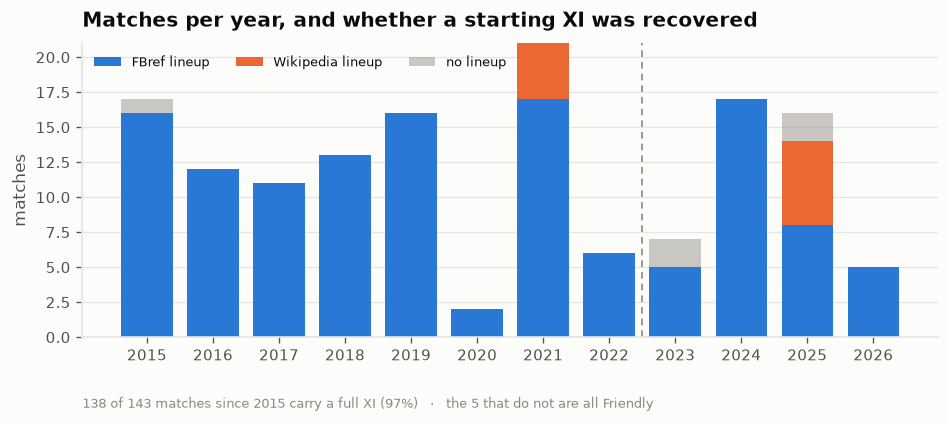

In [3]:
cov = mt[mt.date >= START].copy()
cov["yr"] = cov.date.dt.year
tab = (cov.assign(fb=cov.source.eq("fbref") & cov.has_xi,
                  wk=cov.source.eq("wikipedia") & cov.has_xi,
                  none=~cov.has_xi)
       .groupby("yr")[["fb", "wk", "none"]].sum())

fig, ax = plt.subplots(figsize=(7.8, 3.4))
ax.bar(tab.index, tab.fb, color=viz.BLUE, label="FBref lineup", zorder=2,
       width=0.78)
ax.bar(tab.index, tab.wk, bottom=tab.fb, color=viz.ORANGE, width=0.78,
       label="Wikipedia lineup", zorder=2)
ax.bar(tab.index, tab.none, bottom=tab.fb + tab.wk, width=0.78,
       color=viz.INK_MUTED, alpha=0.45, label="no lineup", zorder=2)
ax.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
ax.set_title("Matches per year, and whether a starting XI was recovered")
ax.set_ylabel("matches")
ax.set_xticks(tab.index)
ax.legend(loc="upper left", ncols=3, fontsize=8)
GAPS = cov[~cov.has_xi].groupby("tournament").size()
ax.annotate(f"{int(cov.has_xi.sum())} of {len(cov)} matches since 2015 carry a "
            f"full XI ({cov.has_xi.mean():.0%})   ·   the "
            f"{int((~cov.has_xi).sum())} that do not are all "
            f"{' and '.join(GAPS.index)}",
            xy=(0, -0.24), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

The remaining gaps are **friendlies whose FBref report carries no lineup**.
There is no source for them: Wikipedia's results articles carry match metadata
and scorers but no lineups, which was checked directly.

## 3. What each column is, and how complete it is

The match table is deliberately wide, because it has to serve both *what
happened in this match* and *who was on the pitch*.

**Plotted:** each column of the match table, sorted by the share of all matches
where it holds a value. Blue is effectively complete (≥90%), orange has real
holes (50–90%), grey is not usable on its own (<50%).

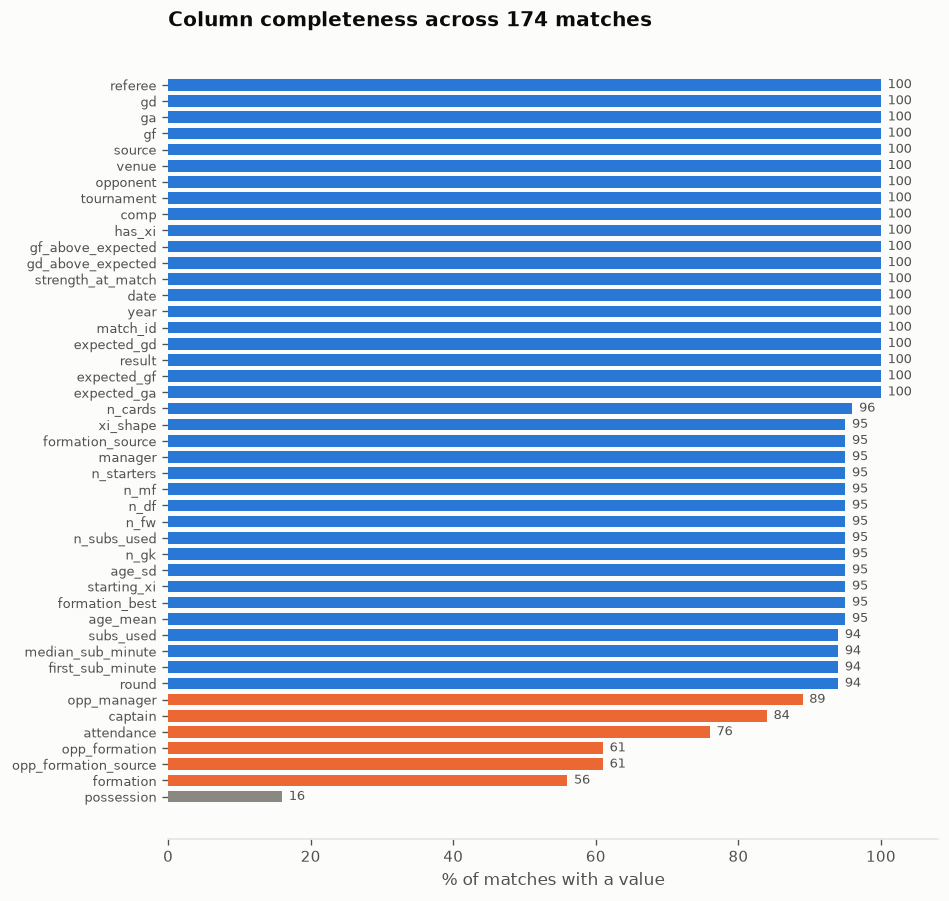

In [4]:
groups = {
    "identity": ["match_id", "date", "year", "comp", "round", "tournament",
                 "opponent", "venue", "source"],
    "result": ["gf", "ga", "gd", "result"],
    "model expectation": ["expected_gf", "expected_ga", "expected_gd",
                          "gf_above_expected", "gd_above_expected",
                          "strength_at_match"],
    "the XI": ["n_starters", "has_xi", "starting_xi", "subs_used", "age_mean",
               "age_sd", "n_gk", "n_df", "n_mf", "n_fw"],
    "shape": ["formation", "opp_formation", "formation_best", "formation_source",
              "opp_formation_source", "xi_shape"],
    "in-match": ["n_subs_used", "first_sub_minute", "median_sub_minute",
                 "n_cards", "captain", "manager", "opp_manager"],
    "context": ["attendance", "referee", "possession"],
}
rows = [{"group": g, "column": c, "pct": round(100 * mt[c].notna().mean())}
        for g, cols in groups.items() for c in cols if c in mt.columns]
completeness = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.8, 7.4))
d = completeness.sort_values("pct").reset_index(drop=True)
# thresholds set where the meaning changes, not on round numbers: at or above 90
# is effectively complete, 50-90 has real holes, below 50 is not usable alone
colour = np.where(d.pct >= 90, viz.BLUE,
                  np.where(d.pct >= 50, viz.ORANGE, viz.INK_MUTED))
ax.barh(np.arange(len(d)), d.pct, color=colour, zorder=2, height=0.72)
ax.set_yticks(np.arange(len(d)))
ax.set_yticklabels(d.column, fontsize=8)
ax.set_xlim(0, 108)
ax.set_title(f"Column completeness across {len(mt)} matches")
ax.set_xlabel("% of matches with a value")
for i, r in d.iterrows():
    ax.annotate(f"{r.pct:.0f}", xy=(r.pct, i), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=7.5,
                color=viz.INK_2)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
plt.show()

Three columns sit low, each for a different reason and none of them fixable:

| column | why |
|---|---|
| `possession` | 27 of 174. Gated by **competition**, never recorded for friendlies — Asian Cup 14/14, World Cup 3/3, WCQ 10/50, friendlies 0/83. Checked against six sources and closed. |
| `formation` | 97 of 174 from FBref. `formation_best` raises it to 166 with a shape derived from the stated positions — kept as a separate column, because a derived shape and a reported one are not the same measurement. |
| `attendance` | the Wikipedia articles leave it blank too. |

## 4. The boundary this data will not cross

FBref's per-player columns exist for every season, but **empty renders as 0**.
Jordan beat Cambodia 7–0 in 2017 and every `Ast` cell in that report reads 0;
assists were not recorded in that era. Applied per match the rule deletes real
data — a 0 for penalties in a match with no penalty is a true zero — so it is
applied **per column per season** instead.

Two things then make the advanced columns unusable *across the 2022 boundary*,
rather than merely thin. FBref changed provider from **StatsBomb to Opta** near
the treatment date; and coverage is gated by competition, which itself changed.

**Plotted, left:** for each advanced column, the share of Jordan appearance rows
holding a non-zero value, before and after mid-2022. **Right:** the share of
open-play goals with a named assister, the same two eras. A column that jumps
here is measuring *collection*, not football — which is why none of them is used
anywhere later.

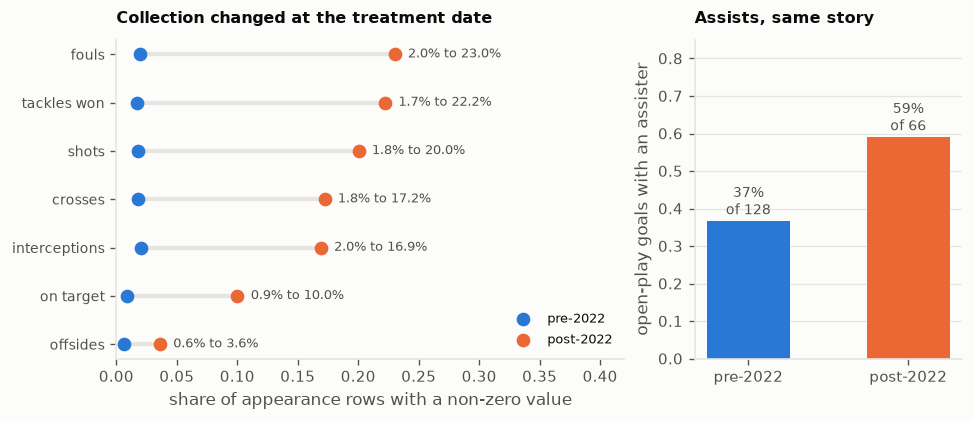

In [5]:
ja = apps[apps.squad_id == "3e22f0fa"].copy()
ja["date"] = ja.match_id.map(mt.set_index("match_id").date)
ja = ja[ja.date >= START]
ja["era"] = np.where(ja.date < CUT, "pre", "post")
# assists are left out here and given the right-hand panel instead: per
# appearance row they are rare for everyone, so the row would read as a small
# jump when the measure that matters is per goal
CAND = [("Performance Sh", "shots"), ("Performance SoT", "on target"),
        ("Performance Crs", "crosses"), ("Performance TklW", "tackles won"),
        ("Performance Int", "interceptions"), ("Performance Off", "offsides"),
        ("Performance Fls", "fouls")]
rows = []
for c, lab in CAND:
    v = pd.to_numeric(ja[c], errors="coerce").fillna(0)
    r = ja.assign(v=v).groupby("era").v.apply(lambda s: (s > 0).mean())
    rows.append({"col": lab, "pre": r.get("pre", 0), "post": r.get("post", 0)})
advc = pd.DataFrame(rows).sort_values("post")

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4),
                         gridspec_kw={"width_ratios": [1.9, 1]})
a = axes[0]
y = np.arange(len(advc))
a.hlines(y, advc.pre, advc.post, color=viz.GRID, lw=2.6, zorder=1)
a.scatter(advc.pre, y, color=viz.BLUE, s=52, zorder=3, label="pre-2022")
a.scatter(advc.post, y, color=viz.ORANGE, s=52, zorder=3, label="post-2022")
for i, r in enumerate(advc.itertuples()):
    a.annotate(f"{r.pre:.1%} to {r.post:.1%}", (max(r.pre, r.post), i),
               xytext=(8, 0), va="center", textcoords="offset points",
               fontsize=7.5, color=viz.INK_2)
a.set_yticks(y)
a.set_yticklabels(advc.col, fontsize=8.5)
a.set_xlim(0, 0.42)
a.set_xlabel("share of appearance rows with a non-zero value")
a.set_title("Collection changed at the treatment date", fontsize=9.5)
a.legend(fontsize=8, loc="lower right")
viz.despine(a)
a.grid(axis="y", visible=False)

b = axes[1]
op = goals[(goals.date >= START) & goals.type.ne("penalty_goal")].copy()
op["era"] = np.where(op.date < CUT, "pre", "post")
asr = op.groupby("era").assist.apply(lambda s: s.notna().mean()).reindex(["pre", "post"])
asn = op.groupby("era").size().reindex(["pre", "post"])
b.bar([0, 1], asr.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, (v, n_) in enumerate(zip(asr.values, asn.values)):
    b.annotate(f"{v:.0%}" + chr(10) + f"of {n_}", (i, v), xytext=(0, 4),
               ha="center", textcoords="offset points", fontsize=8.5,
               color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, 0.85)
b.set_ylabel("open-play goals with an assister")
b.set_title("Assists, same story", fontsize=9.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

🚨 **Every one of these columns multiplies across the boundary.** Shots go from
under 2% of appearance rows to 20%; assists on open-play goals from 37% to 59%.
Comparing Jordan's pre and post eras on any of them would compare *coverage*,
not football.

So everything that follows uses only **structural facts** — who started, for how
long, who scored, at what minute, and what the scoreboard said. Those are
recorded the same way in both eras. There is no expected-goals model, no
possession measure and no passing network anywhere in this project's
conclusions, and this is why.

## 5. A subtler version of the same trap: the words changed

`Pos` is the position printed on **that match's** team sheet. It is not a
player's role, and its *vocabulary* drifted: FBref's coarse DF/MF/FW gave way to
CB, LB, DM, LWB and the rest as the seasons went on.

**Plotted:** the share of starter rows each year whose position is a *specific*
label (CB, LB, DM, LWB…) rather than a coarse one (DF, MF, FW). Marker area is
that year's number of starter rows. One recording convention, changing across
2017–19 — years before the treatment date.

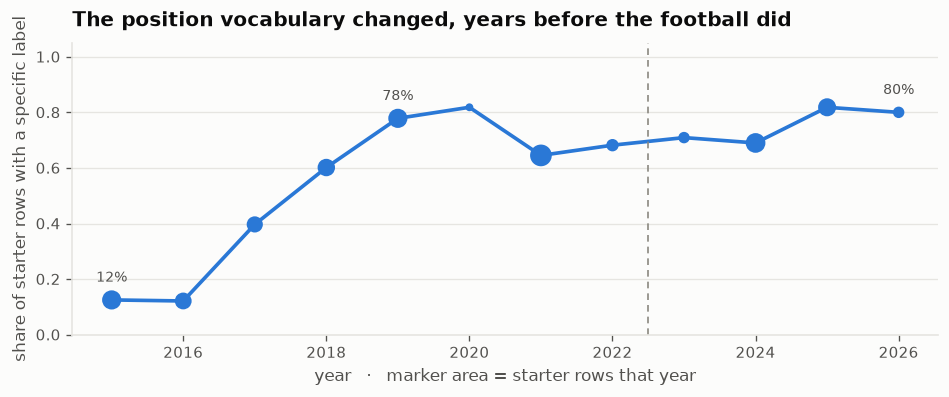

In [6]:
st = ja[ja.role.eq("starter")].copy()


def is_specific(p):
    p = str(p).split(",")[0]
    return p not in ("GK", "DF", "MF", "FW", "nan", "None")


lab = (st.assign(y=st.date.dt.year, s=st.Pos.map(is_specific))
       .groupby("y").s.agg(["mean", "size"]))

fig, ax = plt.subplots(figsize=(7.8, 3.2))
ax.plot(lab.index, lab["mean"], color=viz.BLUE, lw=2.2, zorder=2)
ax.scatter(lab.index, lab["mean"], color=viz.BLUE, s=lab["size"] / 1.6, zorder=3)
ax.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
for y_ in (int(lab.index.min()), 2019, int(lab.index.max())):
    v = lab.loc[y_, "mean"]
    ax.annotate(f"{v:.0%}", (y_, v), xytext=(0, 11), ha="center",
                textcoords="offset points", fontsize=8.5, color=viz.INK_2)
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of starter rows with a specific label")
ax.set_xlabel("year   ·   marker area = starter rows that year")
ax.set_title("The position vocabulary changed, years before the football did")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

🚨 **This one cost a finding.** "Jordan scores more goals from midfield after
2022" was reported with an interval and is **retired**: it is largely the same
relabelling. Ali Olwan — a striker by every other measure — supplies five of the
eighteen post-2022 "midfield" open-play goals, because full-backs became
wing-backs and were written down as LM and RM.

| MF share of open-play goals | pre | post | change |
|---|---|---|---|
| by the team-sheet label | 0.194 | 0.340 | **+0.146** |
| by the scorer's usual position | 0.113 | 0.151 | **+0.038** |

Notebook 04 rebuilds the measure on each player's **modal** position and shows
both answers side by side. The general rule this project now applies: *a column
that describes a player must be resolved at player level, never at row level.*

## 6. Never key a player by name

Arabic names are re-transliterated between sources and between seasons — FBref
writes *Nizar Al Rashdan*, Wikipedia *Nizar Al-Rashdan*, the Arab Cup articles
use bare surnames. Grouping by name splits one man into several players, invents
debuts, and corrupts every continuity measure in notebook 03.

Everything here keys on FBref's 8-hex player id, present on every lineup and
stats row. The six Arab Cup names with no id are listed in
`arabcup_name_crosswalk.csv` with a suggested match and a similarity score, and
are deliberately **left unmerged** — a close string is not proof.

Managers are the exception that proves the rule: FBref gives them no id at all,
so they are name-keyed and every spell was checked by hand. `Abdulla Mesfer` and
`Abdullah Ahmed Mesfer` are one man, merged through an explicit alias dict
rather than a fuzzy match.

## 7. Do the goals add up?

A goal table that does not reconcile against the scoreline is wrong somewhere.
This is the single most important check in the squad layer, because it is the
one an outsider can repeat from a results table.

**Plotted:** for each venue type, the number of matches (grey) against the number
whose goal rows reconcile exactly with the scoreline in the spine (blue). The
neutral row is the one that matters — it is a third of Jordan's fixtures, and
the field FBref uses to attribute goals is null for all of them.

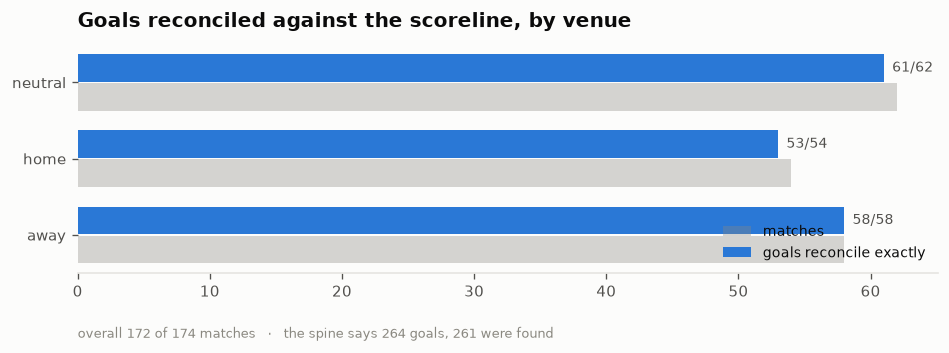

In [7]:
cnt = goals.groupby("match_id").size().rename("found")
chk = mt.merge(cnt, on="match_id", how="left")
chk["found"] = chk.found.fillna(0).astype(int)
chk = chk[chk.gf.notna()].copy()
chk["ok"] = chk.found == chk.gf
by_venue = chk.groupby("venue").agg(matches=("ok", "size"),
                                    reconcile=("ok", "sum"),
                                    goals=("gf", "sum"), found=("found", "sum"))

fig, ax = plt.subplots(figsize=(7.8, 2.8))
y = np.arange(len(by_venue))
ax.barh(y - 0.19, by_venue.matches, height=0.36, color=viz.INK_MUTED,
        alpha=0.35, label="matches", zorder=2)
ax.barh(y + 0.19, by_venue.reconcile, height=0.36, color=viz.BLUE,
        label="goals reconcile exactly", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(by_venue.index)
ax.set_title("Goals reconciled against the scoreline, by venue")
ax.legend(loc="lower right", fontsize=8.5)
for i, r in enumerate(by_venue.itertuples()):
    ax.annotate(f"{r.reconcile}/{r.matches}", xy=(r.reconcile, i + 0.19),
                xytext=(5, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=viz.INK_2)
ax.annotate(f"overall {int(chk.ok.sum())} of {len(chk)} matches   ·   "
            f"the spine says {int(chk.gf.sum())} goals, "
            f"{int(chk.found.sum())} were found",
            xy=(0, -0.28), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
plt.show()

🚨 **The neutral row is the trap.** Jordan plays a third of its matches on
neutral ground — every Asian Cup and World Cup fixture — and FBref's event feed
leaves the `side` field **null** for all of them. Attributing goals by that field
would have silently dropped every one, biasing precisely the period under study.
Goals are instead attributed by checking the scorer against Jordan's own
appearance list for that match.

Two related traps in the same feed, both verified against the 2026
Austria–Jordan report:

- FBref labels own goals and penalty goals with the same trailing text as real
  substitutions (`Penalty Kick — Substitute`). Classify on the text **before**
  the em dash, or two goals become substitutions.
- An own goal is filed under the team that *benefits*, so `side` is the scoring
  team while `player` is the opponent who scored it.

## 8. The scoreboard through each match

`match_state.py` reconstructs, minute by minute, whether Jordan was leading,
level or trailing — from goal minutes on **both** sides. It is what notebook 04's
timing analysis rests on, and its coverage had to be checked before anything
built on it was believed.

**Plotted, left:** matches with and without a reconstructed scoreboard, by era —
the share is now within a point of equal. **Right:** the representativeness
check — the average result-above-expectation of covered against uncovered
matches. The uncovered bars rest on ten and five matches respectively, labelled,
because that is what decides how much to read into them.

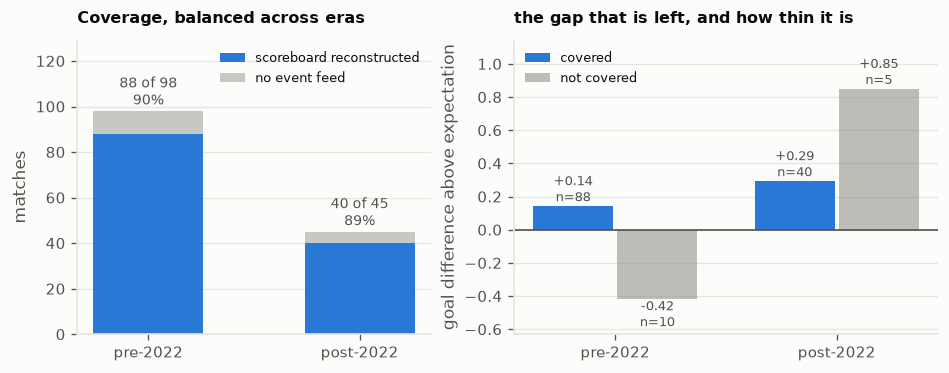

In [8]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
have = set(ms[ms.jordan_side.notna()].match_id)
w = mt[mt.date >= START].copy()
w["era"] = np.where(w.date < CUT, "pre", "post")
w["covered"] = w.match_id.isin(have)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1, 1.2]})
a = axes[0]
t = pd.crosstab(w.era, w.covered).reindex(["pre", "post"])
x = np.arange(2)
a.bar(x, t[True], width=0.52, color=viz.BLUE, label="scoreboard reconstructed")
a.bar(x, t[False], bottom=t[True], width=0.52, color=viz.INK_MUTED, alpha=0.45,
      label="no event feed")
for i, e in enumerate(["pre", "post"]):
    a.annotate(f"{t.loc[e, True]} of {t.loc[e].sum()}" + chr(10)
               + f"{t.loc[e, True] / t.loc[e].sum():.0%}",
               (i, t.loc[e].sum()), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(["pre-2022", "post-2022"])
a.set_ylim(0, t.sum(axis=1).max() * 1.32)
a.set_ylabel("matches")
a.set_title("Coverage, balanced across eras", fontsize=9.5)
a.legend(fontsize=7.5, loc="upper right")
viz.despine(a)
a.grid(axis="x", visible=False)

b = axes[1]
g = w.groupby(["era", "covered"]).gd_above_expected.mean().unstack()
g = g.reindex(["pre", "post"])
for off, col_, lab_ in ((-0.19, True, "covered"), (0.19, False, "not covered")):
    b.bar(x + off, g[col_].values, width=0.36,
          color=viz.BLUE if col_ else viz.INK_MUTED, label=lab_,
          alpha=1.0 if col_ else 0.55)
    ns = w[w.covered == col_].groupby("era").size().reindex(["pre", "post"])
    for xi_, v, n_ in zip(x + off, g[col_].values, ns.values):
        b.annotate(f"{v:+.2f}" + chr(10) + f"n={int(n_)}", (xi_, v),
                   xytext=(0, 3 if v >= 0 else -16), ha="center",
                   textcoords="offset points", fontsize=8, color=viz.INK_2)
b.axhline(0, color=viz.INK_2, lw=1.0)
b.set_xticks(x)
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(g.values.min() * 1.5, g.values.max() * 1.35)
b.set_ylabel("goal difference above expectation")
b.set_title("the gap that is left, and how thin it is", fontsize=9.5)
b.legend(fontsize=7.5)
viz.despine(b)
b.grid(axis="x", visible=False)
plt.show()

🚨 **This figure is the reason the Arab Cup was scraped.** An earlier version of
the feed covered 145 matches and returned a clean null on everything. It was
wrong — not because the numbers were wrong, but because the covered subset was
not representative:

| | n | goal difference above expectation |
|---|---|---|
| post-2022, with event data | 34 | **+0.126** |
| post-2022, without | **11** | **+1.062** |

FBref carries no Arab Cup, so the entire 2025 run — UAE, Kuwait, Egypt, Iraq,
Saudi Arabia, Morocco — plus the 2024 Asian Cup draw with South Korea sat outside
the feed. On covered matches the improvement read as *no improvement at all*,
because the improvement lived in the matches the feed could not see.

**What the repair actually bought, stated honestly.** The coverage *share* is now
90% before 2022 and 89% after, where it was 86% against 76% — so the comparison
is no longer between two differently-observed eras. The uncovered post-era
matches still average higher than the covered ones (**+0.85 against +0.29**), but
that is **five matches** against forty, where it was eleven against thirty-four.
The bias is not eliminated, it is reduced to something five matches can carry.
Read the right-hand panel as "a residual worth remembering", not as "fixed".

**The general rule, which this project keeps relearning: check that the covered
subset is representative before reporting a null.** The same failure hit
possession and opponent formation; only one of the three could be repaired at
all.

## 9. One match, end to end

The clearest test of a dataset is whether a single row can be read and checked
against the outside world. This is the one deliberately non-graphical output in
the project — a receipt, not an analysis.

In [9]:
def show(date):
    r = mt[mt.date == date].iloc[0]
    rnd = f", {r['round']}" if pd.notna(r["round"]) else ""
    print(f"{r.date:%Y-%m-%d}  Jordan {int(r.gf)}-{int(r.ga)} {r.opponent}"
          f"   [{r.comp}{rnd}]   source: {r.source}")
    print(f"  venue {r.venue} | {r.referee} | manager {r.manager} "
          f"({r.manager_side_source})")
    print(f"  formation {r.formation_best} ({r.formation_source})"
          f" | derived shape {r.xi_shape} | XI age {r.age_mean:.1f}")
    print(f"  model expected {r.expected_gf:.2f}-{r.expected_ga:.2f}"
          f" -> {r.gd_above_expected:+.2f} goal difference above expectation")
    print(f"  subs {int(r.n_subs_used)} (first {r.first_sub_minute:.0f}')"
          f" | cards {int(r.n_cards)}")
    print("  starting XI")
    for p in json.loads(r.starting_xi):
        print(f"    {str(p['no']):>2}  {p['name']:<26} {p['pos']:<6}"
              f" {p['min']}'  age {p['age']}")
    gs = goals[goals.match_id == r.match_id]
    if len(gs):
        print("  goals")
        for _, g in gs.iterrows():
            extra = f" (assist {g.assist})" if pd.notna(g.assist) else ""
            print(f"    {int(g.minute):>3}'  {g.scorer}{extra}  [{g.type}]")


show("2025-12-18")

2025-12-18  Jordan 2-3 Morocco   [Arab Cup]   source: wikipedia
  venue neutral | Glenn Nyberg | manager Jamal Sellami (source)
  formation 3-4-3 (derived_from_lineup) | derived shape 3-4-3 | XI age 27.6
  model expected 0.47-1.57 -> +0.10 goal difference above expectation
  subs 6 (first 46') | cards 2
  starting XI
     1  Yazeed Abulaila            GK     119'  age 32.9
     3  Abdallah Nasib             DF     119'  age 31.8
    19  Saed Al-Rosan              DF     119'  age 28.9
    21  Nizar Al Rashdan           MF     119'  age 26.7
    20  Mohannad Abu Taha          MF     119'  age 22.9
     9  Ali Olwan                  FW     119'  age 25.7
     4  Husam Abu Dahab            DF     104'  age 25.6
    13  Mahmoud Al-Mardi           FW     90'  age 32.2
     6  Amer Jamous                MF     81'  age 23.5
    17  Issam Smeeri               MF     46'  age 26.6
     7  Mohammad Aburiziq          FW     46'  age 26.9
  goals
     48'  Ali Olwan  [goal]
     68'  Ali Olwan  [

That is the 2025 Arab Cup final — one of the **ten matches with no FBref record
at all**. Lineup, minutes, cards, captain and scorers are all recovered from the
Wikipedia match article, and the scoreline agrees with the spine.

## 10. What this data can and cannot be asked

**Can**: who started, for how long, at what age; how the XI changed between
matches; who scored, at what minute, from which position; where those players
played their club football; how many substitutes and when; what the scoreboard
said through each match; how the result compared with what the model expected.

**Cannot**: anything needing shots, possession or ball location across the 2022
boundary — section 4. *"Did Jordan create more chances?"* is unanswerable, and no
further sourcing changes that.

### Sources checked and rejected

Recorded so they are not re-explored. Each failed for the reason given.

| source | verdict |
|---|---|
| RSSSF | 23 of 67 players have match pages; coverage 64% (2011) → 13% (2025). Al-Taamari and Al-Naimat have none. |
| Wikipedia player pages | 137 of 184 have no international by-year table, and the tables are truncated at source (Ali Olwan shows 31 caps against 59 actual). The parser was validated — the source is what is incomplete. |
| API-Football | The only complete option. Free tier serves 2022–2024 only; Pro would backfill everything in ~460 requests. Terms forbid redistributing raw data. |
| StatsBomb open | Rich, but La Liga is a Barcelona-only dataset and there is no Jordan. |
| Understat, FootyStats, Google panel | robots.txt or terms of service forbid it. |
| football-data.co.uk, openfootball | Domestic leagues, or scores with no minutes. Fine as a spine, no squad data. |
| AFC technical reports | A 95-page narrative, not a dataset. |
| Possession, six sources | 27 of 174 matches and **cannot be completed** — the measurement was never taken for most of Jordan's fixtures. 0% (2011-14) rising to 44% (2023-26); a partial fill would put the coverage boundary on the treatment date. |

**Still missing, and known to be non-random:** FBref does not track WAFF (6
matches), the Palestine International Championship (4), the King's Cup (2) or the
Jordan International Tournament (2). All are competitive and several are
rotation-heavy — so squad turnover measured in notebook 03 is biased slightly
**downward**. The ten Arab Cup matches, which were the largest part of this hole,
are now in.

---

**Next:** notebook 02 asks the question this data was assembled for — did
Jordan's results actually shift, once the opponent is accounted for?